# Exposure-Aware Air Quality Health Risk Forecasting

Forecasting next-week pollution health risk (**Low / Moderate / High**) for
Indian cities from daily multi-pollutant measurements, 2015-2020.

> **This notebook is a corrected rebuild.** An earlier version of this analysis
> reported **89% accuracy**. That number was an artifact: the label was a 7-day
> rolling mean of the exposure score, while the features were 3-day and 1-day
> statistics of *that same series*. The task was reconstructing a smoothed
> series from its own components, not forecasting.
>
> Rebuilt as genuine forecasting, the honest result is **0.756 macro F1 /
> 0.751 accuracy** -- and only **+0.019 macro F1 above a trivial persistence
> rule**. The complete defect-by-defect accounting is in
> [`FIXES.md`](../FIXES.md); the pre-fix notebook remains in git history.

**The task.** At day *t*, using only data from day *t* and earlier, predict the
risk level of mean exposure over days **t+1 ... t+7**. Feature windows end at
*t*; the label window starts at *t+1*. They never overlap.

Heavy lifting lives in the `pipeline` package so the same code is covered by
`verify_no_leakage.py`; this notebook is the narrative over it.

In [1]:
import sys
from pathlib import Path

# The package lives at the repo root, one level up from notebooks/.
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipeline import config as cfg
from pipeline import data as data_mod
from pipeline import features as feat
from pipeline import models as mdl

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
print("horizon:", cfg.LABEL_HORIZON_DAYS, "days   test starts:", cfg.TEST_START)

horizon: 7 days   test starts: 2019-10-01


## 1. Load and audit

The original imputed missing pollutants with city-wise medians and moved on.
That hides how bad the gaps actually are, so the audit comes first.

In [2]:
raw = data_mod.load_raw()
print(f"{len(raw):,} rows | {raw.City.nunique()} cities | "
      f"{raw.Date.min().date()} -> {raw.Date.max().date()}")

miss = (raw.groupby("City")[cfg.CORE_POLLUTANTS]
           .apply(lambda g: g.isna().mean() * 100)
           .round(1))
miss.loc[miss.max(axis=1).sort_values(ascending=False).index].head(10)

29,531 rows | 26 cities | 2015-01-01 -> 2020-07-01


,PM2.5,PM10,NO2,SO2,CO,O3
City,,,,,,
Lucknow,5.1,100.0,1.2,3.2,1.4,1.3
Ernakulam,2.5,2.5,34.0,2.5,2.5,100.0
Patna,17.3,89.7,11.0,11.0,8.1,15.0
Chennai,5.8,85.0,1.8,1.8,1.2,2.4
Ahmedabad,31.3,79.7,30.3,31.9,30.3,34.1
Jorapokhar,67.6,23.5,23.1,30.0,43.9,25.1
Mumbai,61.0,62.0,62.4,60.7,1.2,60.3
Gurugram,9.2,55.9,8.1,10.4,6.5,6.9
Brajrajnagar,19.7,18.4,24.9,20.6,16.0,21.6


Some of these are unusable, not merely sparse: **Lucknow's PM10 is 100%
missing**, Patna's is 90%, Chennai's 85%, and Mumbai is ~60% absent across most
pollutants. Median-filling a column that is 85-100% empty produces a constant
masquerading as a measurement.

So instead of imputing pollutant values, the composite score renormalises its
weights over whichever pollutants were **actually observed** on each row, and
rows without enough observed weight get no score at all.

In [3]:
df, report = data_mod.build_clean_frame()

print(f"max calendar gap inside any city : {report['max_calendar_gap_days']} days")
print(f"dropped, history < {cfg.MIN_CITY_OBSERVATIONS}d      : {report['dropped_insufficient_history']}")
print(f"dropped, coverage < {cfg.MIN_CITY_VALID_RATE:.0%}       : {report['dropped_poor_coverage']}")
print(f"rows flagged unscoreable         : {report['rows_flagged_low_coverage']:,}")
print(f"retained                         : {len(report['cities_retained'])} cities, {report['rows_retained']:,} rows")

max calendar gap inside any city : 0 days
dropped, history < 365d      : ['Aizawl', 'Bhopal', 'Chandigarh', 'Ernakulam', 'Kochi', 'Shillong']
dropped, coverage < 70%       : {'Ahmedabad': 0.698, 'Mumbai': 0.394}
rows flagged unscoreable         : 1,656
retained                         : 18 cities, 24,173 rows


Two notes on the gates:

- **Zero calendar gaps** inside any city. That is worth asserting rather than
  assuming, because `.rolling(7)` counts *rows*: with missing dates a "7-day"
  window would silently span more than 7 days.
- Rows failing the coverage gate are **flagged, not dropped**. Dropping them
  would break that contiguity. Keeping them with a NaN score means an
  incomplete window stays incomplete, which is what `min_periods=window`
  exists to catch.

## 2. Temporal split

The original called its split chronological. It was not:
`train_test_split(shuffle=False)` on a frame sorted by `['City','Date']` holds
out the **alphabetically last cities**, entire -- so there was no temporal
validation at all in a project premised on temporal exposure.

This is a real date cutoff. Training rows whose label window would reach past
the cutoff are discarded, so no training label is built from a test-period day.

In [4]:
test_start = pd.Timestamp(cfg.TEST_START)
train_end = test_start - pd.Timedelta(days=cfg.EMBARGO_DAYS)

is_train = df["Date"] < train_end
is_test = df["Date"] >= test_start

print(f"train   {df.loc[is_train,'Date'].min().date()} -> {df.loc[is_train,'Date'].max().date()}")
print(f"embargo {train_end.date()} -> {test_start.date()}  ({cfg.EMBARGO_DAYS} days discarded)")
print(f"test    {df.loc[is_test,'Date'].min().date()} -> {df.loc[is_test,'Date'].max().date()}")
print()
print(f"cities in train: {df.loc[is_train,'City'].nunique()} | "
      f"in test: {df.loc[is_test,'City'].nunique()} | "
      f"test-only: {len(set(df.loc[is_test,'City']) - set(df.loc[is_train,'City']))}")

train   2015-01-01 -> 2019-09-23
embargo 2019-09-24 -> 2019-10-01  (7 days discarded)
test    2019-10-01 -> 2020-07-01

cities in train: 18 | in test: 18 | test-only: 0


## 3. Composite exposure score

A weighted blend of six pollutants (PM2.5 0.35, PM10 0.20, NO2 0.15, and
SO2 / CO / O3 at 0.10 each).

The original applied those weights to **min-max scaled** values, which quietly
broke the scheme. These distributions have extreme tails, so min-max crushes
ordinary days into a sliver near zero and a pollutant's nominal weight stops
matching its real contribution.

In [5]:
desc = df[cfg.CORE_POLLUTANTS].describe().loc[["25%", "50%", "75%", "max"]].T
desc["max / p75"] = (desc["max"] / desc["75%"]).round(1)
desc.round(2)

,25%,50%,75%,max,max / p75
PM2.5,30.00,49.83,83.06,949.99,11.4
PM10,58.23,98.22,155.13,1000.00,6.4
NO2,11.85,21.51,36.44,362.21,9.9
SO2,5.43,8.57,13.92,187.02,13.4
CO,0.54,0.89,1.36,48.07,35.3
O3,19.04,30.51,44.84,257.73,5.7


CO reaches **175 against a 75th percentile of 1.5**; PM10 hits 1000 against 130.
Under min-max, CO's nominal 0.10 weight contributes almost no variance.

Percentile ranking fixes it: outlier-robust, bounded in [0, 1], and each
pollutant contributes in proportion to its weight. The transform is fitted on
**training rows only**.

In [6]:
ranker = feat.fit_pollutant_ranker(df.loc[is_train])
df = feat.apply_composite_score(df, ranker)

# What min-max would have done to the same column, for comparison.
co = df["CO"].dropna()
minmax = (co - co.min()) / (co.max() - co.min())
ranked = pd.Series(ranker.transform(df[cfg.CORE_POLLUTANTS])[:, 4], index=df.index).dropna()

print(f"CO under min-max     : median {minmax.median():.4f}, p95 {minmax.quantile(.95):.4f}")
print(f"CO under percentile  : median {ranked.median():.4f}, p95 {ranked.quantile(.95):.4f}")
print()
print(df["hrs"].describe().round(4).to_string())

CO under min-max     : median 0.0185, p95 0.0605
CO under percentile  : median 0.4840, p95 0.9389

count    22517.0000
mean         0.4916
std          0.2058
min          0.0208
25%          0.3254
50%          0.4840
75%          0.6525
max          0.9854


## 4. Causal features

Every feature ends at day *t*. Windows must be **complete** -- the original used
`min_periods=1`, so a row's "7-day mean" could be a single day.

Volatility is computed on the **raw** daily score. The original computed it on a
series that had been accidentally overwritten by its own 7-day rolling mean, so
the "volatility" feature measured the variability of smoothed data -- close to
the opposite of its name.

In [7]:
df = feat.add_causal_features(df)

print(f"{len(feat.FEATURE_COLUMNS)} features:")
for c in feat.FEATURE_COLUMNS:
    print("  ", c)

17 features:
   hrs_mean_3
   hrs_mean_7
   hrs_mean_14
   hrs_mean_30
   hrs_std_7
   hrs_std_14
   hrs_lag_1
   hrs_lag_7
   hrs_trend
   month_sin
   month_cos
   dow_sin
   dow_cos
   is_winter
   voc_index
   voc_observed
   weight_coverage


Calendar terms are **cyclical**. As raw integers (the original's approach)
December = 12 and January = 1 sit at opposite ends of the range despite being
adjacent seasons, which actively misleads a linear model.

## 5. Forward-looking target

**This is the correction that matters.**

`rolling(H).mean()` at row *i* covers `[i-H+1 .. i]`; shifting by `-H` moves it
to row *i-H*, giving the mean of `[i+1 .. i+H]` at row *i*. Requiring a complete
window means each city's final H days have no label and drop out -- correct,
since their future is not in the dataset.

Thresholds come from **training exposure only**. The original computed those
quantiles over the whole dataset, so the label definition itself encoded the
test distribution.

In [8]:
df = feat.add_forward_target(df)

hrs_feats = [c for c in feat.FEATURE_COLUMNS if c.startswith("hrs_")]
complete = df[hrs_feats].notna().all(axis=1) & df["target_exposure"].notna()

lo, hi = feat.fit_risk_thresholds(df.loc[is_train & complete, "target_exposure"])
lo_all, hi_all = feat.fit_risk_thresholds(df.loc[complete, "target_exposure"])
df["risk"] = feat.apply_risk_labels(df["target_exposure"], lo, hi)

print(f"train-only thresholds : {lo:.4f} / {hi:.4f}")
print(f"full-data thresholds  : {lo_all:.4f} / {hi_all:.4f}   <- what the original used")
print(f"rows with complete history and a label: {int(complete.sum()):,} of {len(df):,}")

train-only thresholds : 0.4032 / 0.5935
full-data thresholds  : 0.3941 / 0.5805   <- what the original used
rows with complete history and a label: 19,955 of 24,173


Confirming the label really is the forward window, by recomputing it by hand for
one city rather than trusting the vectorised expression:

In [9]:
h = cfg.LABEL_HORIZON_DAYS
city = df.loc[df.hrs.notna()].groupby("City").size().idxmax()
g = df[df.City == city].sort_values("Date").reset_index(drop=True)

manual, stored = [], []
for i in range(len(g) - h):
    w = g["hrs"].iloc[i + 1 : i + 1 + h]
    if w.notna().all() and pd.notna(g["target_exposure"].iloc[i]):
        manual.append(w.mean()); stored.append(g["target_exposure"].iloc[i])

print(f"{city}: {len(manual):,} rows checked")
print(f"max |manual - stored| = {np.abs(np.array(manual) - np.array(stored)).max():.2e}")
print(f"label at t == mean(hrs[t+1..t+{h}]):", np.allclose(manual, stored))

Delhi: 2,002 rows checked
max |manual - stored| = 3.33e-16
label at t == mean(hrs[t+1..t+7]): True


In [10]:
train = df[is_train & complete]
test = df[is_test & complete]
X_train, y_train = train[feat.FEATURE_COLUMNS], train["risk"].to_numpy()
X_test, y_test = test[feat.FEATURE_COLUMNS], test["risk"].to_numpy()

print(f"train {len(X_train):,} rows | test {len(X_test):,} rows")
print()
balance = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(normalize=True),
    "test": pd.Series(y_test).value_counts(normalize=True),
}).reindex(cfg.RISK_LABELS)
(balance * 100).round(1)

train 15,368 rows | test 4,482 rows



,train,test
Low,33.0,38.9
Moderate,33.0,33.9
High,34.0,27.2


Train is balanced by construction -- the classes are training-set terciles, so
"~33% each" is a tautology of the binning, not a property of the data. Test
drifts away from it, which is what an honest held-out future looks like.

## 6. Baselines

The original reported 89% against **nothing at all**. For a forecasting task the
bar that matters is **persistence** -- "next week looks like this week."
Pollution exposure is strongly autocorrelated, so persistence is hard to beat,
and any evaluation omitting it will overstate the model's contribution.

In [11]:
maj_metrics, _ = mdl.majority_baseline(y_train, y_test)
pers_metrics, _ = mdl.persistence_baseline(test["hrs_mean_7"], lo, hi, y_test)

print(f"majority class   acc {maj_metrics['accuracy']:.3f}   macro F1 {maj_metrics['macro_f1']:.3f}")
print(f"persistence      acc {pers_metrics['accuracy']:.3f}   macro F1 {pers_metrics['macro_f1']:.3f}")

majority class   acc 0.272   macro F1 0.142
persistence      acc 0.737   macro F1 0.737


## 7. Models

Both estimators sit inside sklearn `Pipeline`s, so imputation and scaling are
refitted per training fold instead of being fitted on the full dataset.

The original fitted logistic regression on **unscaled** features spanning very
different ranges, which handicapped it and made the 86%-vs-89% comparison
meaningless.

In [12]:
logit = mdl.build_logistic().fit(X_train, y_train)
logit_rep = mdl.full_report("logistic_regression", logit, X_train, y_train, X_test, y_test)
print(f"train macro F1 {logit_rep['train']['macro_f1']:.3f} | "
      f"test macro F1 {logit_rep['test']['macro_f1']:.3f} | "
      f"test acc {logit_rep['test']['accuracy']:.3f}")

train macro F1 0.801 | test macro F1 0.750 | test acc 0.748


The forest is tuned with **forward-chaining `TimeSeriesSplit`** on macro F1, so
each fold validates on a period strictly later than it trained on. The original
hardcoded `max_depth=50, n_estimators=200` with no search, no cross-validation
and no training score -- so overfitting was invisible. (This cell runs a real
grid search and takes a few minutes.)

In [13]:
search = mdl.tune_random_forest(X_train, y_train, train["Date"])
rf = search.best_estimator_
rf_rep = mdl.full_report("random_forest", rf, X_train, y_train, X_test, y_test)

print(f"best params     : {search.best_params_}")
print(f"best CV macro F1: {search.best_score_:.3f}")
print(f"train macro F1 {rf_rep['train']['macro_f1']:.3f} | "
      f"test macro F1 {rf_rep['test']['macro_f1']:.3f} | "
      f"test acc {rf_rep['test']['accuracy']:.3f}")

best params     : {'clf__max_depth': 4, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__n_estimators': 600}
best CV macro F1: 0.775
train macro F1 0.800 | test macro F1 0.756 | test acc 0.751


Tuning selects a **heavily regularised** forest -- shallow depth, not the
original's depth-50 -- and the train-vs-test gap is now visible rather than
hidden.

In [14]:
comparison = pd.DataFrame([
    ("majority class", maj_metrics["accuracy"], maj_metrics["macro_f1"]),
    ("persistence", pers_metrics["accuracy"], pers_metrics["macro_f1"]),
    ("logistic regression", logit_rep["test"]["accuracy"], logit_rep["test"]["macro_f1"]),
    ("random forest", rf_rep["test"]["accuracy"], rf_rep["test"]["macro_f1"]),
], columns=["model", "accuracy", "macro F1"]).set_index("model")

lift = rf_rep["test"]["macro_f1"] - pers_metrics["macro_f1"]
print(f"random forest beats persistence by {lift:+.3f} macro F1\n")
comparison.round(3)

random forest beats persistence by +0.018 macro F1



,accuracy,macro F1
model,,
majority class,0.272,0.142
persistence,0.737,0.737
logistic regression,0.748,0.750
random forest,0.751,0.756


**The honest headline: the tuned model beats persistence by about two macro-F1
points.** Most of what looks like predictive skill is inertia. That is a far
less impressive result than 89%, and a far more useful one -- it says what this
data can actually support.

## 8. Interpretation

Errors are almost entirely between **adjacent** classes.

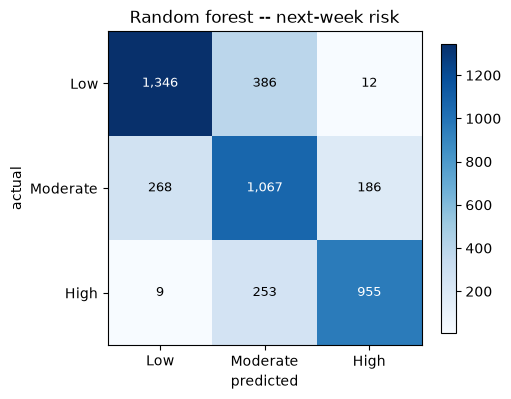

,precision,recall,f1-score,support
Low,0.829,0.772,0.800,1744.0
Moderate,0.625,0.702,0.661,1521.0
High,0.828,0.785,0.806,1217.0


In [15]:
cm = np.array(rf_rep["confusion_matrix"])
labels = rf_rep["confusion_labels"]

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), labels); ax.set_yticks(range(3), labels)
ax.set_xlabel("predicted"); ax.set_ylabel("actual")
ax.set_title("Random forest -- next-week risk")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); plt.show()

pd.DataFrame(rf_rep["test_report"]).T.loc[labels, ["precision", "recall", "f1-score", "support"]].round(3)

Low-vs-High confusion is negligible in both directions, out of ~4,500 test days.
**Moderate** is the weak class because it is bounded on both sides -- the same
structural pattern as the `CANDIDATE` class in my
[Kepler KOI project](https://github.com/ayazzahmad/kepler-koi-classification),
and for the same reason: a middle band defined by thresholds is intrinsically
fuzzier than the extremes.

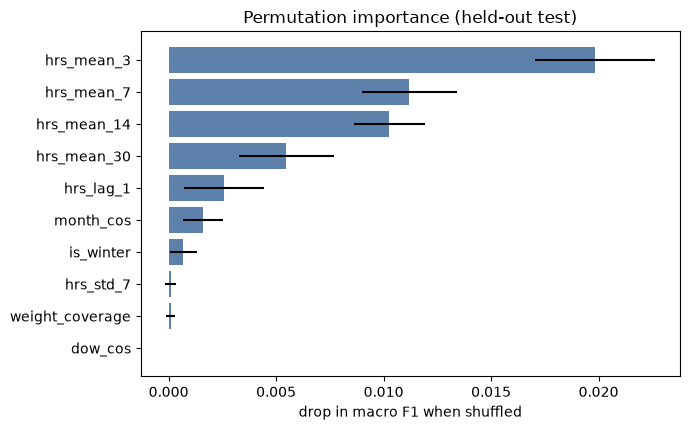

,feature,importance,std
0,hrs_mean_3,0.0198,0.0028
1,hrs_mean_7,0.0112,0.0022
2,hrs_mean_14,0.0103,0.0016
3,hrs_mean_30,0.0055,0.0022
4,hrs_lag_1,0.0026,0.0018
5,month_cos,0.0016,0.0009
6,is_winter,0.0007,0.0006
7,hrs_std_7,0.0001,0.0003
8,weight_coverage,0.0001,0.0002
9,dow_cos,0.0000,0.0000


In [16]:
imp = mdl.importance_report(rf, X_test, y_test)

fig, ax = plt.subplots(figsize=(7, 4.4))
top = imp.head(10).iloc[::-1]
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#5e81ac")
ax.set_xlabel("drop in macro F1 when shuffled")
ax.set_title("Permutation importance (held-out test)")
fig.tight_layout(); plt.show()

imp.head(10).round(4)

Permutation importance on **held-out** data, rather than the training-set
impurity importance the original used. Two of the original write-up's stated
findings do not survive:

- **Volatility carries essentially no signal.** The original claimed it
  "provides secondary but meaningful signal" -- but that feature had been
  computed on an accidentally-smoothed series, so the claim could not have been
  assessed properly anyway.
- **No day-of-week effect.** Both cyclical terms sit at zero.

All importances are small in absolute terms, consistent with the narrow margin
over persistence: the rolling means carry largely redundant information, so
removing any single one costs little. The original's headline insight -- that
"short-term accumulated exposure dominates predictions" -- was a mechanical
consequence of building the label from `HRS_3day`'s own window.

### Distribution shift

India's COVID-19 lockdown (2020-03-25) falls inside the test window and changed
air quality sharply, so metrics are reported on both sides of it rather than
blended into a single figure.

In [17]:
covid = pd.Timestamp(cfg.COVID_START)
pers_pred = feat.apply_risk_labels(test["hrs_mean_7"], lo, hi).to_numpy()
rf_pred = rf.predict(X_test)

rows = []
for name, m in [("pre-lockdown", (test["Date"] < covid).to_numpy()),
                ("lockdown", (test["Date"] >= covid).to_numpy())]:
    rows.append({
        "segment": name, "n": int(m.sum()),
        "persistence": mdl.score(y_test[m], pers_pred[m])["macro_f1"],
        "random forest": mdl.score(y_test[m], rf_pred[m])["macro_f1"],
    })
shift = pd.DataFrame(rows).set_index("segment")
shift["RF - persistence"] = shift["random forest"] - shift["persistence"]
shift.round(3)

,n,persistence,random forest,RF - persistence
segment,,,,
pre-lockdown,3018,0.695,0.710,0.015
lockdown,1464,0.634,0.657,0.023


Both degrade under the regime change. The model's margin over persistence widens
slightly during lockdown -- when yesterday stops being a good guide to tomorrow,
the extra features earn a little more of their keep.

## Conclusions

Rebuilt as a genuine forecasting task, this pipeline reaches **0.756 macro F1 /
0.751 accuracy** on a held-out future, against **0.737** for a one-line
persistence rule.

What changed, and why the number fell from 89%:

1. The label was built from the same rolling window as its features. Now the
   feature window ends at *t* and the label covers *t+1 ... t+7*.
2. The "chronological" split was alphabetical by city. Now a real date cutoff
   with a 7-day embargo.
3. Label thresholds, the scaler and the imputer were all fitted on the full
   dataset. Now train-only, inside pipelines.
4. There was no baseline. Persistence is now the reference point.

**Honest limitations.** The margin over persistence is small -- this is a modest
improvement on inertia, not a strong forecaster. Labels are relative exposure
terciles, not clinical thresholds, and this dataset contains no health outcomes,
so "health risk" is a proxy throughout. Pollutant weights are hand-assigned. No
meteorology. One pooled model across 18 cities that differ substantially. The
test window contains a structural break.

Invariants are checked by [`verify_no_leakage.py`](../verify_no_leakage.py);
the full defect list is in [`FIXES.md`](../FIXES.md).